# 📈 기대수명 예측하기 (교과서 191쪽 ~ 200쪽)
**IV. 인공지능 프로젝트 > 2. 정형 데이터 인공지능 프로젝트 실제 1**

## 🎯 학습 목표
1. 인공지능 프로젝트의 **전체 절차**(문제 정의 → 데이터 수집 → 전처리 → 시각화·분석 → 알고리즘 선정 → 학습 → 평가 → 개선 → 활용)를 직접 따라 할 수 있다.
2. **결측치**를 찾아 처리하고, **히스토그램·히트맵·산점도·바이올린 그래프**로 데이터의 특징을 해석할 수 있다.
3. **선형 회귀** 모델을 학습시키고, **결정계수(R²)** 와 **평균 절대 오차(MAE)** 로 성능을 평가할 수 있다.
4. 사용하는 **속성(feature)을 바꾸어** 모델 성능이 어떻게 달라지는지 비교·설명할 수 있다.

## 🗺️ 전체 절차 한눈에 보기
| 단계 | 하는 일 | 사용하는 도구 |
|---|---|---|
| [0] 실습 환경 확인 | 실행 환경(로컬/코랩) 확인, 라이브러리 확인, 한글 글꼴 설정 | VS Code + .venv 또는 Colab |
| [1] 문제 정의 | 무엇을 예측할지 정하기 | - |
| [2] 데이터 수집 | 데이터 파일 준비(로컬: 같은 폴더 / 코랩: 업로드) → 불러오기 | pandas |
| [3] 데이터 전처리 | 데이터 확인 → 열 이름 정리 → 결측치 처리 → 범주형(글자)을 숫자로 바꾸기 | pandas |
| [4] 데이터 시각화 및 분석 | 히스토그램, 히트맵, 산점도, 바이올린 그래프 | matplotlib, seaborn, plotly |
| [5] 기계학습 유형과 알고리즘 선정 | 지도학습·회귀, 선형 회귀 / 데이터 나누기 | scikit-learn |
| [6] 모델 학습 | 선형 회귀 모델 학습, 가중치·편향 확인 | scikit-learn |
| [7] 성능 평가 | 결정계수(R²), 평균 절대 오차(MAE) | scikit-learn |
| [8] 수정 및 성능 개선 | 한 개의 속성으로 회귀선 그리기, 속성 바꾸어 비교 | scikit-learn |
| [9] 모델 활용 | 새로운 값으로 기대수명 예측하기 | - |
| [10] 정리 및 생각 넓히기 | 상관관계와 인과관계 | - |

> 📌 **실행 방법 (VS Code)**
> * 오른쪽 위 **[커널 선택(Select Kernel)]** 에서 반드시 **`.venv`** 가상환경을 고르세요.
> * 위에서부터 **차례대로** 셀을 실행하세요. (셀 선택 후 `Shift + Enter`)
> * 중간 셀을 건너뛰면 오류가 날 수 있어요. 오류가 나면 위쪽 도구 모음의 **[다시 시작(Restart)] → [모두 실행(Run All)]** 을 해 보세요.
> * VS Code를 껐다 켜면 변수가 모두 사라집니다. **다시 접속했을 때는 맨 위 셀부터 다시 실행**해야 해요.
>
> ☁️ **코랩(Colab)에서 실행할 때** : 커널 선택 없이 그대로 실행하면 됩니다. [0]단계에서 코랩인지 자동으로 확인하고, [2]단계에서 **데이터 파일 업로드 창**이 나타나요.
>
> ✏️ 표시가 있는 곳이 **과제**입니다. 코드 칸은 `# 여기에 코드를 작성하세요` 부분을, 글 칸은 **더블클릭**해서 답을 쓰고 `Esc`(또는 ✔ 버튼)로 저장하세요.

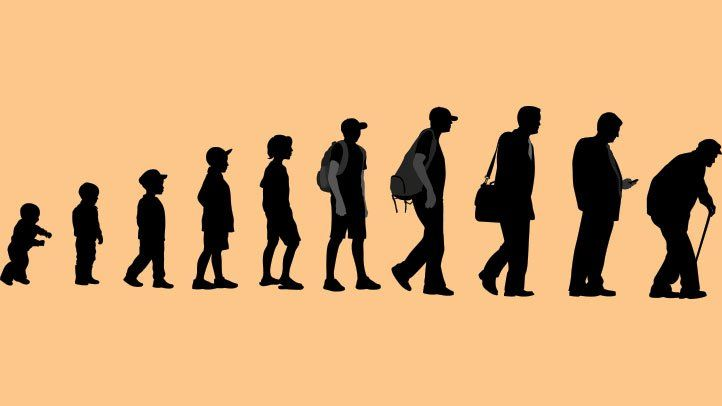

# **[0] 실습 환경 확인하기**
> 이 노트북은 **두 가지 환경**에서 모두 실행할 수 있도록 만들었습니다. 코드가 지금 어느 환경인지 **스스로 알아내서** 알맞게 동작해요.
>
> | 구분 | 로컬 환경 (VS Code + 가상환경) | 코랩 환경 (Google Colab) |
> |---|---|---|
> | 실행 위치 | 내 컴퓨터 | 구글의 인터넷 서버 |
> | 라이브러리 | `pip install -r requirements.txt` 로 직접 설치 | 대부분 이미 설치되어 있음 |
> | 데이터 파일 | 노트북과 **같은 폴더**에 CSV 넣어 두기 | 실행할 때마다 CSV **업로드** 필요 (런타임이 끊기면 사라짐) |
> | 한글 글꼴 | 윈도우 기본 글꼴(맑은 고딕) 사용 | 나눔 글꼴을 설치해서 사용 |

## ① 실행 환경(로컬 / 코랩) 확인하기
* 코랩에서 실행하면 `google.colab` 이라는 코랩 전용 라이브러리가 들어 있습니다. 이것을 가져올(import) 수 있는지로 코랩인지 아닌지를 구분합니다.
* `IN_COLAB` 변수에 **코랩이면 `True`, 내 컴퓨터(로컬)이면 `False`** 를 저장해 두고, 아래 셀들에서 계속 사용합니다.
* 로컬 환경이면 **`sys.executable`(파이썬 프로그램의 위치)** 에 **`.venv`** 가 들어 있는지도 확인합니다.

In [ ]:
import sys                                   # 파이썬 실행 환경 정보를 알려 주는 기본 라이브러리
import os                                    # 폴더·파일을 다루는 기본 라이브러리

try:
    import google.colab                      # 코랩에만 있는 라이브러리
    IN_COLAB = True                          # 가져오기에 성공하면 → 코랩 환경
except ImportError:
    IN_COLAB = False                         # 실패하면 → 로컬(내 컴퓨터) 환경

print('파이썬 버전 :', sys.version.split()[0])
print('현재 폴더   :', os.getcwd())

if IN_COLAB:
    print('\n☁️ 코랩(Colab) 환경에서 실행 중입니다.')
    print('   → [2]단계에서 데이터 파일을 업로드해야 합니다.')
else:
    print('\n💻 로컬(내 컴퓨터) 환경에서 실행 중입니다.')
    print('파이썬 위치 :', sys.executable)    # 이 경로에 .venv 가 들어 있어야 함
    if '.venv' in sys.executable:
        print('✅ 가상환경(.venv) 커널로 실행 중입니다. 다음 셀로 가세요!')
    else:
        print('⚠️ 가상환경 커널이 아닙니다. 오른쪽 위 [커널 선택] → [Python 환경] → .venv 를 선택하세요.')

## ② 실습에 필요한 라이브러리 확인하기
* **로컬 환경** : 아래 셀에서 오류(`ModuleNotFoundError`)가 나면, VS Code **터미널**에서 가상환경을 켠 상태로 다음 명령을 실행한 뒤 **커널을 다시 시작**하세요.
```
pip install -r requirements.txt
```
* **코랩 환경** : 필요한 라이브러리가 이미 설치되어 있으므로 그대로 실행하면 됩니다.

In [ ]:
import numpy as np                 # 숫자 계산(배열) 라이브러리
import pandas as pd                # 표(데이터프레임) 데이터를 다루는 라이브러리
import matplotlib                  # 그래프를 그리는 기본 라이브러리
import matplotlib.pyplot as plt
import seaborn as sns              # 통계 그래프를 쉽게 그려 주는 라이브러리
import plotly                      # 마우스로 움직일 수 있는(인터랙티브) 그래프 라이브러리
import sklearn                     # 기계학습 라이브러리(scikit-learn)

print('numpy       :', np.__version__)
print('pandas      :', pd.__version__)
print('matplotlib  :', matplotlib.__version__)
print('seaborn     :', sns.__version__)
print('plotly      :', plotly.__version__)
print('scikit-learn:', sklearn.__version__)
print('\n✅ 라이브러리가 모두 준비되었습니다!')

## ③ 그래프에서 한글이 깨지지 않게 설정하기
* matplotlib은 기본 글꼴에 한글이 없어서 한글이 **□□□** 로 보입니다. 환경에 맞는 한글 글꼴을 지정해 줍니다.
  * **코랩** : 리눅스 서버라 한글 글꼴이 없으므로 **나눔 글꼴을 설치**한 뒤 등록합니다. (처음 실행할 때 10초 정도 걸려요.)
  * **로컬(윈도우/맥)** : 컴퓨터에 이미 있는 맑은 고딕 / 애플고딕을 사용합니다.
* `unicode_minus=False` : 음수 기호(-)가 깨지는 것을 막아 줍니다.

In [ ]:
import platform                                    # 운영체제(Windows, macOS 등)를 알려 주는 라이브러리
import matplotlib.font_manager as fm               # 글꼴을 관리하는 도구

if IN_COLAB:
    # 코랩: 나눔 글꼴 설치(처음 한 번) → matplotlib에 등록
    font_path = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
    if not os.path.exists(font_path):
        os.system('apt-get -qq install -y fonts-nanum > /dev/null')
    fm.fontManager.addfont(font_path)
    plt.rc('font', family='NanumGothic')
elif platform.system() == 'Windows':
    plt.rc('font', family='Malgun Gothic')          # 윈도우: 맑은 고딕
elif platform.system() == 'Darwin':
    plt.rc('font', family='AppleGothic')            # 맥: 애플고딕
plt.rc('axes', unicode_minus=False)                # 음수 기호 깨짐 방지
print('한글 글꼴 설정 완료:', plt.rcParams['font.family'])

# **[1] 문제 정의**
### 한 나라의 보건·경제·교육 정보를 이용하여 그 나라의 **기대수명**을 예측할 수 있을까?

* 나라의 **여러 정보**(성인 사망률, 예방 접종률, 1인당 GDP, 교육 기간 등)를 **입력**하면,
* 그 나라 사람들의 **기대수명(살 것으로 예상되는 평균 나이)** 을 **숫자로 출력**하는 모델을 만듭니다.
* 정답(기대수명)이 붙어 있는 데이터로 학습하므로 **지도학습**이고, 정답이 종류가 아니라 **연속된 숫자**이므로 **회귀(Regression)** 문제입니다.

```
[성인 사망률, 예방 접종률, GDP, 교육 기간, ...]  →  🤖 모델  →  72.5 (세)
```

| 구분 | 분류(Classification) | 회귀(Regression) |
|---|---|---|
| 맞히는 값 | 정해진 **종류** 중 하나 | 연속된 **숫자** |
| 예시 | 펭귄의 종 (Adelie / Chinstrap / Gentoo) | **기대수명 (72.5세)**, 집값, 기온 |

## 📂 실습 데이터 : 세계보건기구(WHO) GHO(Global Health Observatory) 데이터
* **Life Expectancy Dataset** : 2000년~2015년, 193개국의 기대수명과 건강 요인 관련 데이터
* 실습 파일 : `Life Expectancy Data.csv` (이 노트북과 **같은 폴더**에 있어야 합니다.)
* 원본 내려받기 : 교과서 QR코드 또는 [캐글(Kaggle)](https://www.kaggle.com/datasets/kumarajarshi/life-expectancy-who)

### 데이터 속성(열) 설명
* **변수 구분** : 모델이 맞혀야 하는 정답은 **종속 변수(y)**, 정답을 예측하는 데 쓰는 정보는 **독립 변수(X)** 입니다.
* **자료 유형** : 정해진 몇 가지 **종류(이름표)** 중 하나인 값은 **범주형**, 크기를 비교하고 계산할 수 있는 **숫자** 값은 **수치형**입니다.
  * 범주형 값은 모델이 계산할 수 없으므로 [3]단계에서 **숫자로 바꾸거나(인코딩)** 학습에서 **제외**합니다.

| 열 이름 | 뜻 | 변수 구분 | 자료 유형 |
|---|---|---|---|
| `Country` | 국가 이름 | 제외 (학습에 사용 안 함) | 범주형 |
| `Year` | 연도 | 독립 변수(X) | 수치형 |
| `Status` | 개발 상태 : 개발도상국(Developing) / 선진국(Developed) | 독립 변수(X) | 범주형 → 0/1로 인코딩 |
| **`Life expectancy`** | **기대수명(세) → 우리가 맞혀야 할 정답(종속 변수, target)** | **종속 변수(y)** | **수치형** |
| `Adult Mortality` | 성인 사망률 (인구 1,000명당 15~60세 사이에 사망할 확률) | 독립 변수(X) | 수치형 |
| `infant deaths` | 인구 1,000명당 유아 사망 수 | 독립 변수(X) | 수치형 |
| `Alcohol` | 15세 이상 1인당 알코올 소비량(순수 알코올 리터) | 독립 변수(X) | 수치형 |
| `percentage expenditure` | 1인당 GDP 대비 보건 지출 비율(%) | 독립 변수(X) | 수치형 |
| `Hepatitis B` | 1세 아동의 B형 간염 예방 접종률(%) | 독립 변수(X) | 수치형 |
| `Measles` | 인구 1,000명당 보고된 홍역 환자 수 | 독립 변수(X) | 수치형 |
| `BMI` | 전체 인구의 평균 체질량 지수 | 독립 변수(X) | 수치형 |
| `under-five deaths` | 인구 1,000명당 5세 미만 사망 수 | 독립 변수(X) | 수치형 |
| `Polio` | 1세 아동의 소아마비 예방 접종률(%) | 독립 변수(X) | 수치형 |
| `Total expenditure` | 정부 총지출 대비 보건 분야 지출 비율(%) | 독립 변수(X) | 수치형 |
| `Diphtheria` | 1세 아동의 디프테리아·백일해 예방 접종률(%) | 독립 변수(X) | 수치형 |
| `HIV/AIDS` | 출생 1,000명당 HIV/AIDS 사망 수(0~4세) | 독립 변수(X) | 수치형 |
| `GDP` | 1인당 국내 총생산(USD) | 독립 변수(X) | 수치형 |
| `Population` | 국가 총인구 수 | 독립 변수(X) | 수치형 |
| `thinness  1-19 years` | 1~19세 아동·청소년의 야윔(저체중) 비율 | 독립 변수(X) | 수치형 |
| `thinness 5-9 years` | 5~9세 아동의 야윔(저체중) 비율 | 독립 변수(X) | 수치형 |
| `Income composition of resources` | 소득 기준 인간개발지수 (0~1, 1에 가까울수록 발전) | 독립 변수(X) | 수치형 |
| `Schooling` | 교육 기간(년) | 독립 변수(X) | 수치형 |

> 정리 : 전체 22개 열 = **종속 변수 1개** (`Life expectancy`) + **독립 변수 20개** (수치형 19개 + 범주형 `Status` 1개) + **제외 1개** (`Country`)

### 🔍 심화 탐구 주제 (실습하면서 생각해 보세요. [10]단계에서 하나를 골라 답합니다.)
- 처음에 선택한 다양한 예측 요인이 실제로 수명에 영향을 미치는가?
- 기대수명에 실제로 영향을 미치는 예측 변수는 무엇인가?
- 기대수명이 낮은(65세 미만) 국가에서 평균수명을 늘리려면 의료비 지출을 늘려야 할까?
- 유아 및 성인 사망률은 기대수명에 어떤 영향을 주는가?
- 학교 교육(교육 기간)이 기대수명에 미치는 영향은 무엇인가?
- 기대수명은 음주와 긍정적 또는 부정적 관계가 있는가?
- 인구가 많은 국가는 기대수명이 낮은 경향이 있는가?
- 예방 접종이 기대수명에 미치는 영향은 무엇인가?

# **[2] 데이터 수집**
> 실행 환경에 따라 데이터 파일을 준비하는 방법이 다릅니다. 아래 셀이 `IN_COLAB` 값을 보고 **알아서 구분**해 줍니다.
>
> * 💻 **로컬 환경** : `Life Expectancy Data.csv` 를 노트북과 **같은 폴더**에 넣어 두기만 하면 됩니다.
> * ☁️ **코랩 환경** : 셀을 실행하면 **[파일 선택]** 버튼이 나타납니다. 버튼을 눌러 내 컴퓨터의 CSV 파일을 고르면 업로드됩니다.
>   (코랩에 올린 파일은 **런타임이 끊기면 사라지므로**, 다시 접속하면 또 업로드해야 해요.)

## ① 데이터 파일 준비하기

In [ ]:
file_name = 'Life Expectancy Data.csv'      # 읽어 올 데이터 파일 이름

if os.path.exists(file_name):               # 이미 파일이 있으면 (로컬, 또는 코랩에서 이미 업로드함)
    print(f'✅ {file_name} 파일이 준비되어 있습니다. 다음 단계로 가세요!')

elif IN_COLAB:                              # ☁️ 코랩인데 파일이 없으면 → 업로드 창 열기
    from google.colab import files          # 코랩 전용 파일 업로드 도구
    print(f'☁️ [파일 선택] 버튼을 눌러 {file_name} 파일을 업로드하세요.')
    uploaded = files.upload()               # 업로드 창 열기 → 고른 파일이 현재 폴더에 저장됨
    for name in uploaded:                   # 이름이 'Life Expectancy Data (1).csv' 처럼 바뀌어 올라온 경우 이름 맞추기
        if name != file_name and name.endswith('.csv'):
            os.rename(name, file_name)
    if os.path.exists(file_name):
        print(f'✅ {file_name} 업로드 완료! 다음 단계로 가세요.')
    else:
        print('⚠️ 업로드한 파일이 없습니다. 이 셀을 다시 실행해서 CSV 파일을 올려 주세요.')

else:                                       # 💻 로컬인데 파일이 없으면 → 안내
    print(f'⚠️ {file_name} 파일이 없습니다!')
    print('   → 이 노트북(.ipynb)과 같은 폴더에 CSV 파일을 복사한 뒤 다시 실행하세요.')
    print('   → 현재 폴더:', os.getcwd())

## ② 데이터 불러오기
* `pd.read_csv('파일이름')` : CSV 파일을 읽어서 **데이터프레임(표)** 으로 만들어 줍니다.
* 읽어 온 표를 `df`(DataFrame의 줄임말)라는 변수에 저장합니다.

In [ ]:
df = pd.read_csv(file_name)     # CSV 파일을 읽어 df 변수에 저장
print('데이터 불러오기 완료!')

# **[3] 데이터 전처리**
> **전처리**란 모델이 잘 학습할 수 있도록 데이터를 **확인하고, 정리하고, 다듬는** 과정입니다.
> 실제 인공지능 프로젝트에서 가장 많은 시간이 걸리는 단계예요!

## ① 데이터셋 정보 확인하기
* `info()` : 행(데이터 개수)과 열(속성) 정보, **비어 있지 않은 값의 개수(Non-Null Count)**, 자료형을 보여 줍니다.
  * 전체는 2938개인데 Non-Null Count가 그보다 작은 열이 있다면 → **빈 값(결측치)** 이 있다는 뜻!
  * `object` 는 글자(문자열), `int64` 는 정수, `float64` 는 소수(실수) 자료형입니다.

In [ ]:
df.info()        # 데이터의 전체 구조(행/열 개수, 결측치 여부, 자료형) 확인

* `head()` : 데이터의 **앞부분 5줄**을 보여 줍니다. `NaN` 은 값이 비어 있다는 표시입니다.

In [ ]:
df.head()        # 앞의 5개 행 미리 보기 (괄호 안에 숫자를 넣으면 그만큼 보여 줌. 예: df.head(10))

* `describe()` : 숫자 열의 **요약 통계**를 보여 줍니다.
  * count(개수), mean(평균), std(표준편차: 흩어진 정도), min(최솟값), 25%/50%/75%(사분위수), max(최댓값)
  * `Population`(인구)처럼 숫자가 매우 큰 열과 `Income composition of resources`(0~1)처럼 작은 열이 섞여 있다는 점을 눈여겨보세요.

In [ ]:
df.describe()    # 숫자 열의 평균, 최솟값, 최댓값 등 요약 통계

## ② 열 이름 정리하기
* 이 데이터의 열 이름 중에는 `' BMI'` 처럼 **앞뒤에 공백(빈칸)** 이 숨어 있는 것이 있습니다.
* 공백이 있으면 `df['BMI']` 로 불렀을 때 **KeyError** 가 나므로, `str.strip()` 으로 열 이름 앞뒤의 공백을 없애 줍니다.

In [ ]:
print('정리 전:', list(df.columns)[9:12])    # ' BMI' 앞에 공백이 있음
df.columns = df.columns.str.strip()          # 모든 열 이름의 앞뒤 공백 제거
print('정리 후:', list(df.columns)[9:12])

---

### ✏️ 과제 1. 데이터 살펴보기
아래 질문에 답하는 코드를 작성하고 실행해 보세요.
1. 이 데이터는 몇 행, 몇 열로 이루어져 있나요? (힌트: `df.shape`)
2. 몇 개 나라의 데이터인가요? (힌트: `df['Country'].nunique()` → 겹치지 않는 값의 개수)
3. 데이터는 몇 년부터 몇 년까지 있나요? (힌트: `df['Year'].min()`, `df['Year'].max()`)
4. 개발도상국(Developing)과 선진국(Developed) 데이터는 각각 몇 개인가요? (힌트: `value_counts()`)

In [ ]:
# 1. 데이터의 (행, 열) 개수 출력하기
# 여기에 코드를 작성하세요


# 2. 나라의 개수 출력하기
# 여기에 코드를 작성하세요


# 3. 가장 처음 연도와 마지막 연도 출력하기
# 여기에 코드를 작성하세요


# 4. 개발 상태(Status)별 데이터 개수 세기
# 여기에 코드를 작성하세요

✏️ 답: 데이터는 ( )행 ( )열이고, ( )개 나라의 ( )년부터 ( )년까지의 데이터이다. 개발도상국은 ( )개, 선진국은 ( )개이다.

---

## ③ 결측치 확인하기
* **결측치(Missing Value)** : 측정하지 못했거나 기록이 빠져서 **비어 있는 값**(`NaN`)
* 모델은 빈 값이 있으면 계산을 할 수 없기 때문에 반드시 처리해야 합니다.
* `isna()` : 각 칸이 비어 있으면 `True`, 값이 있으면 `False` → `sum()` 으로 더하면 열마다 결측치 개수가 나옵니다. (True=1, False=0)

In [ ]:
df.shape         # 결측치 처리 전 (행, 열) 개수

In [ ]:
df.isna().sum()  # 열별 결측치 개수

---

### ✏️ 과제 2. 결측치 분석하기
1. 결측치가 **가장 많은 열 3개**와 각각의 결측치 개수를 출력해 보세요. (힌트: `df.isna().sum().sort_values(ascending=False).head(3)`)
2. 각 열의 결측치가 전체의 **몇 %** 인지 계산해 보세요. (힌트: `df.isna().sum() / len(df) * 100`)

In [ ]:
# 1. 결측치가 가장 많은 열 3개
# 여기에 코드를 작성하세요


# 2. 열별 결측치 비율(%) 계산하기 (소수 첫째 자리까지: .round(1))
# 여기에 코드를 작성하세요

✏️ 답: 결측치가 가장 많은 열은 ( ) ( )개, ( ) ( )개, ( ) ( )개이다.

---

## ④ 결측치 제거하기
* 결측치 처리 방법 : ① 결측치가 있는 행을 **삭제**하기  ② 평균 등 다른 값으로 **채우기**
* 교과서에서는 `dropna()` 로 **결측치가 하나라도 있는 행을 삭제**합니다.

In [ ]:
print('결측치 삭제 전 데이터 개수:', len(df))
df = df.dropna()                 # 결측치가 하나라도 있는 행을 삭제하고 그 결과를 다시 df에 저장
print('결측치 삭제 후 데이터 개수:', len(df))

In [ ]:
df.isna().sum()                  # 다시 확인 → 모두 0이면 결측치 처리 완료!

---

### ✏️ 과제 3. 결측치 삭제의 영향 생각하기
1. 결측치를 삭제한 뒤 **원래 데이터(2938개)의 몇 %** 가 남았는지 계산해 보세요.
2. 삭제 후 남은 **나라의 수**를 출력해 보세요.
3. 결측치가 있는 행을 모두 삭제하는 방법의 **문제점**을 한 가지 써 보세요.

In [ ]:
# 1. 남은 데이터 비율(%) 계산하기
# 여기에 코드를 작성하세요


# 2. 남은 나라의 수 출력하기
# 여기에 코드를 작성하세요

✏️ 답: 데이터의 ( )%가 남았고, 나라는 ( )개가 남았다.

✏️ 3번 답(문제점):

---

## ⑤ 글자로 된 값을 숫자로 바꾸기(인코딩)
* 모델은 **숫자**만 계산할 수 있습니다. `Status` 열의 'Developing', 'Developed' 를 숫자로 바꿉니다.
* 개발도상국(Developing) → **0**, 선진국(Developed) → **1**
* `map({...})` : 괄호 안의 규칙대로 값을 바꾸어 줍니다.

In [ ]:
print('바꾸기 전:', df['Status'].unique().tolist())
df['Status'] = df['Status'].map({'Developing': 0, 'Developed': 1})   # 개발도상국 0, 선진국 1
print('바꾼 후  :', df['Status'].unique().tolist())
df.head()

# **[4] 데이터 시각화 및 분석**
> 숫자로 된 표만 보아서는 데이터의 특징을 알기 어렵습니다. **그래프로 그려 보면** 분포와 관계가 한눈에 보여요!

## ① 기대수명에 대한 히스토그램 시각화하기
* **히스토그램** : 값을 일정한 구간으로 나누고, 각 구간에 **데이터가 몇 개 있는지** 막대로 나타낸 그래프
* 우리가 맞혀야 할 정답(종속 변수 y)인 **기대수명이 어떻게 분포하는지** 확인합니다.

In [ ]:
df['Life expectancy'].hist(bins=30)   # bins=30 : 구간을 30개로 나누기
plt.title('기대수명 분포')
plt.xlabel('기대수명(세)')
plt.ylabel('데이터 개수')
plt.show()

## ② 소아마비 예방 접종률에 대한 히스토그램 시각화하기
* `sns.displot(..., kde=True)` : 히스토그램 위에 **부드러운 곡선(KDE, 밀도 곡선)** 을 함께 그려 분포 모양을 쉽게 볼 수 있게 합니다.
* 대부분의 나라가 접종률이 **높은 쪽(90% 이상)** 에 몰려 있는지 확인해 보세요.

In [ ]:
sns.displot(x=df['Polio'], kde=True)   # 소아마비 예방 접종률 분포 + 밀도 곡선
plt.title('소아마비 예방 접종률 분포')
plt.show()

---

### ✏️ 과제 4. 분포와 그룹 비교하기
1. **교육 기간(`Schooling`)** 의 분포를 `sns.displot` 으로 그려 보세요.
2. **개발도상국(0)과 선진국(1)의 평균 기대수명**을 각각 구해 보세요. (힌트: `df.groupby('Status')['Life expectancy'].mean()`)

In [ ]:
# 1. 교육 기간(Schooling) 분포 그리기
# 여기에 코드를 작성하세요


# 2. 개발 상태별 평균 기대수명 구하기
# 여기에 코드를 작성하세요

✏️ 답: 개발도상국의 평균 기대수명은 ( )세, 선진국은 ( )세로 ( )세 차이가 난다.

---

## ③ 히트맵으로 속성 간 상관관계 파악하기
* **상관계수** : 두 속성이 함께 커지거나 작아지는 정도를 **-1 ~ 1** 사이의 숫자로 나타낸 것
  * **1에 가까울수록** : 한쪽이 커지면 다른 쪽도 커짐 (양의 상관관계, 진한 빨간색)
  * **-1에 가까울수록** : 한쪽이 커지면 다른 쪽은 작아짐 (음의 상관관계)
  * **0에 가까울수록** : 관계가 거의 없음
* `df.corr(numeric_only=True)` : **숫자 열끼리만** 상관계수를 계산합니다. (`Country` 같은 글자 열은 제외)
* 속성이 많아서 그림이 크니, **`Life expectancy` 줄(행)** 을 중심으로 살펴보세요.

In [ ]:
corr = df.corr(numeric_only=True)          # 숫자 열끼리 상관계수 계산

plt.figure(figsize=(15, 12))               # 그래프 크기(가로 15, 세로 12)
sns.heatmap(corr, linewidths=0.1, vmax=1, cmap=plt.cm.YlOrRd, linecolor='white',
            annot=True, fmt='.2f', annot_kws={'size': 7})   # annot=True : 칸에 숫자 표시
plt.title('속성 간 상관관계 히트맵')
plt.show()

* 히트맵은 숫자가 너무 많아서 보기 어렵죠? **기대수명과의 상관계수만** 뽑아서 막대그래프로 정리해 봅시다.
* `sort_values()` : 작은 값부터 큰 값 순서로 정렬합니다.

In [ ]:
corr_life = corr['Life expectancy'].drop('Life expectancy').sort_values()   # 기대수명과의 상관계수(자기 자신 제외)

plt.figure(figsize=(8, 7))
corr_life.plot(kind='barh', color=['tab:blue' if v < 0 else 'tab:red' for v in corr_life])  # 음수는 파랑, 양수는 빨강
plt.title('기대수명과 각 속성의 상관계수')
plt.xlabel('상관계수')
plt.axvline(0, color='black', linewidth=0.8)   # 0 기준선
plt.show()

---

### ✏️ 과제 5. 상관관계 해석하기
1. 기대수명과 **양(+)의 상관관계가 가장 큰 속성**과 **음(-)의 상관관계가 가장 큰 속성**을 출력해 보세요. (힌트: `corr_life` 를 이용, `idxmax()`, `idxmin()`, `max()`, `min()`)
2. 두 속성이 기대수명과 어떤 관계인지 **문장으로 설명**해 보세요.
3. `Population`(인구)과 기대수명의 상관계수는 얼마인가요? 심화 탐구 주제 "인구가 많은 국가는 기대수명이 낮은 경향이 있는가?"에 답해 보세요.

In [ ]:
# 1. 양의 상관관계가 가장 큰 속성과 값 / 음의 상관관계가 가장 큰 속성과 값
# 여기에 코드를 작성하세요


# 3. Population과 기대수명의 상관계수
# 여기에 코드를 작성하세요

✏️ 1번 답: 양의 상관관계가 가장 큰 속성은 ( ) ( ), 음의 상관관계가 가장 큰 속성은 ( ) ( )이다.

✏️ 2번 답:

✏️ 3번 답:

---

## ④ 산점도로 특정 속성 간 상관관계 파악하기
* **페어플롯(pairplot)** : 여러 속성을 **두 개씩 짝지어** 산점도로 그리고, 대각선에는 각 속성의 **분포**를 그려 줍니다.
* `hue='Status'` : 개발도상국(0)과 선진국(1)을 **다른 색**으로 표시합니다.
* 홍역 환자 수(`Measles`), 1인당 GDP(`GDP`), 개발 상태(`Status`), 기대수명의 관계를 살펴봅니다.

In [ ]:
sns.pairplot(data=df[['Measles', 'GDP', 'Status', 'Life expectancy']], hue='Status', palette='bright')
plt.show()

## ⑤ 바이올린 그래프 시각화하기
* **바이올린 그래프** : 데이터가 많이 몰려 있는 곳은 **두껍게**, 적은 곳은 **얇게** 그려 분포 모양을 보여 줍니다. 가운데 상자(box)는 중앙값과 사분위수를 나타냅니다.
* 개발도상국(0)과 선진국(1)의 **기대수명 분포를 비교**합니다.
* plotly 그래프는 **마우스를 올리면 값이 보이는** 인터랙티브 그래프입니다.

> ⚠️ VS Code에서 그래프가 보이지 않으면 : 터미널에서 `pip install nbformat` 실행 → 커널 **다시 시작** → 위에서부터 다시 실행

In [ ]:
import plotly.express as px                                       # plotly의 간단한 그래프 도구
fig = px.violin(df, x='Status', y='Life expectancy', color='Status', box=True,
                title='개발 상태별 기대수명 분포 (0: 개발도상국, 1: 선진국)')
fig.show()

* (참고) plotly 그래프가 계속 보이지 않으면 아래 seaborn 버전으로 그려도 같은 결과를 볼 수 있어요.

In [ ]:
sns.violinplot(data=df, x='Status', y='Life expectancy', hue='Status', palette='bright', legend=False)
plt.title('개발 상태별 기대수명 분포 (0: 개발도상국, 1: 선진국)')
plt.show()

# **[5] 기계학습 유형과 알고리즘 선정**
## ① 기계학습 유형 선정하기
* 정답(기대수명)이 있는 데이터로 학습 → **지도학습**
* 맞혀야 하는 값이 연속된 숫자(나이) → **회귀**

## ② 알고리즘 선정하기 : 선형 회귀(Linear Regression)
* 각 속성에 **가중치(w, weight)** 를 곱해서 모두 더하고, **편향(b, bias)** 을 더해 기대수명을 예측합니다.

$$\hat{y} = w_1x_1 + w_2x_2 + \cdots + w_nx_n + b$$

* 속성이 하나라면 $\hat{y} = wx + b$ → 중학교 때 배운 **일차함수(직선)** 와 같은 모양이에요!
* 학습이란 **실제 정답과 예측값의 차이(오차)가 가장 작아지는** 가중치 w와 편향 b를 찾는 과정입니다.

## ③ 독립 변수(X)와 종속 변수(y) 나누기
* **독립 변수(X, 입력, 문제)** : 기대수명을 예측하는 데 사용하는 정보 → `Life expectancy`, `Country` 를 뺀 **나머지 20개 열**
  * `Country`(나라 이름)는 글자이고, 나라 이름 자체로는 기대수명을 일반화해서 예측할 수 없으므로 뺍니다.
* **종속 변수(y, 출력, 정답)** : 맞혀야 하는 값 → `Life expectancy`
* `drop([...], axis=1)` : 괄호 안의 **열**을 삭제 (axis=1 : 열 방향)

In [ ]:
X = df.drop(['Life expectancy', 'Country'], axis=1)   # 정답과 나라 이름을 뺀 나머지 → 문제(X)
y = df['Life expectancy']                             # 기대수명 → 정답(y)

print('X 크기:', X.shape)    # (데이터 개수, 속성 개수)
print('y 크기:', y.shape)

## ④ 훈련 데이터와 테스트 데이터 분리하기
* **훈련 데이터(train)** : 모델이 **공부**하는 데 사용하는 데이터 (문제집)
* **테스트 데이터(test)** : 학습이 끝난 뒤 **실력을 평가**하는 데 사용하는 데이터 (시험지)
* `test_size=0.2` : 전체의 20%를 테스트 데이터로 사용 (나머지 80%는 훈련 데이터)
* `random_state=96` : 무작위로 섞는 방식을 고정 → **누가 실행해도 같은 결과**가 나오게 함 (교과서와 같은 값)

In [ ]:
from sklearn.model_selection import train_test_split   # 데이터를 훈련용/테스트용으로 나누는 함수

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=96)

In [ ]:
X_train.head()          # 훈련 데이터 앞부분 확인 (행 번호가 뒤섞여 있는 것 = 무작위로 섞였다는 뜻)

In [ ]:
print('X_train:', X_train.shape, ' y_train:', y_train.shape)   # 약 80%
print('X_test :', X_test.shape, ' y_test :', y_test.shape)     # 약 20%

# **[6] 모델 학습**
## ① 모델 생성하기
* `LinearRegression()` : 선형 회귀 모델을 만듭니다. (아직 학습 전이라 아무것도 모르는 상태)

In [ ]:
from sklearn.linear_model import LinearRegression    # 선형 회귀 알고리즘 가져오기
linear_reg = LinearRegression()                      # 선형 회귀 모델 만들기

## ② 모델 학습하기
* `fit(문제, 정답)` : 훈련 데이터로 모델을 **학습**시킵니다. → 가장 좋은 가중치와 편향을 찾음

In [ ]:
lin_results = linear_reg.fit(X_train, y_train)       # 훈련 데이터로 학습
print('학습 완료!')

## ③ 가중치와 편향 확인하기
* `coef_` : 각 속성의 **가중치(w)** 20개,  `intercept_` : **편향(b)**
* 숫자만 나열하면 어느 속성의 가중치인지 알기 어려우므로, **속성 이름과 함께 표**로 정리해 봅니다.

In [ ]:
w = lin_results.coef_          # 가중치(속성 20개 각각에 곱하는 값)
b = lin_results.intercept_     # 편향
print('가중치(w):', w)
print('편향(b):', b)

In [ ]:
# 속성 이름과 가중치를 표로 정리하기
weight_table = pd.DataFrame({'속성': X.columns, '가중치(w)': w.round(4)})
weight_table

---

### ✏️ 과제 6. 가중치 해석하기
1. `weight_table` 에서 **가중치가 가장 큰 속성**과 **가장 작은(음수 쪽으로 큰) 속성**을 찾아보세요. (힌트: `sort_values('가중치(w)')`)
2. `Schooling`(교육 기간)의 가중치는 얼마인가요? 이 값의 뜻을 "다른 조건이 같을 때, 교육 기간이 1년 늘어나면 ..." 으로 시작하는 문장으로 써 보세요.
3. `Income composition of resources` 의 가중치는 아주 크고 `Population` 의 가중치는 거의 0입니다. 그렇다면 **Income composition이 Population보다 수천 배 중요한 속성**이라고 말할 수 있을까요? (힌트: 두 열의 **값의 범위**를 `describe()` 에서 비교해 보세요.)

In [ ]:
# 1. 가중치 순서대로 정렬하기
# 여기에 코드를 작성하세요


# 3. 두 열의 최솟값/최댓값 비교하기
# 여기에 코드를 작성하세요

✏️ 1번 답:

✏️ 2번 답:

✏️ 3번 답:

---

# **[7] 성능 평가**
## ① 결정계수(R²) 확인하기
* `predict(문제)` : 학습한 모델로 테스트 데이터의 기대수명을 **예측**합니다. (정답 `y_test` 는 보여 주지 않음!)
* **결정계수(R², R-squared)** : 모델이 정답의 변화를 **얼마나 잘 설명하는지** 나타내는 점수
  * **1에 가까울수록** 잘 맞힘 (1.0 = 완벽),  **0에 가까울수록** 평균값으로 찍는 것과 비슷한 수준
  * 예) R² = 0.8 → 기대수명 차이의 약 80%를 모델이 설명한다.

In [ ]:
from sklearn.metrics import r2_score                  # 결정계수를 계산하는 함수
y_pred = lin_results.predict(X_test)                  # 테스트 데이터로 기대수명 예측
print('결정계수(R^2) =', r2_score(y_test, y_pred))     # (실제 정답, 예측값) 비교

## ② 테스트 데이터로 평가하기
* 실제 기대수명과 모델이 예측한 기대수명을 **6개만** 나란히 비교해 봅니다.
* `{:.3f}` : 소수 셋째 자리까지 표시,  차이 = 실제 - 예측 (양수면 모델이 더 작게 예측한 것)

In [ ]:
Y_prediction = y_pred.flatten()            # 예측값을 1차원 배열로 펼치기
for i in range(6):                         # 앞에서부터 6개만 반복
    label = y_test.values[i]               # i번째 실제 기대수명
    prediction = Y_prediction[i]           # i번째 예측 기대수명
    print('실제 기대수명: {:.3f}, 학습 후 예측 기대수명: {:.3f}, 차이: {:.3f}'
          .format(label, prediction, label - prediction))

## ③ 실제값과 예측값을 그래프로 비교하기
* 가로축은 실제 기대수명, 세로축은 예측 기대수명입니다.
* 모델이 완벽하다면 모든 점이 **빨간 대각선(실제 = 예측)** 위에 놓입니다. 점들이 대각선에 가까울수록 잘 맞힌 것이에요.

In [ ]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.5)                              # 실제값 vs 예측값
plt.plot([y.min(), y.max()], [y.min(), y.max()], color='red')       # 실제 = 예측 인 대각선
plt.xlabel('실제 기대수명')
plt.ylabel('예측 기대수명')
plt.title('실제 기대수명 vs 예측 기대수명')
plt.show()

---

### ✏️ 과제 7. 평균 절대 오차(MAE)로 평가하기
* **평균 절대 오차(MAE, Mean Absolute Error)** : (실제 - 예측)의 **절댓값**을 모두 더해 평균 낸 값 → "**평균적으로 몇 세 정도 틀렸는가?**"
* 결정계수와 달리 **단위(세)** 가 있어서 이해하기 쉬워요. **0에 가까울수록** 좋은 모델입니다.

1. `y_test` 와 `y_pred` 로 **MAE를 직접 계산**해 보세요. (힌트: `abs(y_test - y_pred).mean()`)
2. 사이킷런의 `mean_absolute_error` 함수로도 계산하여 1번과 같은지 확인해 보세요.

In [ ]:
# 1. MAE 직접 계산하기
# 여기에 코드를 작성하세요


# 2. 사이킷런 함수로 계산하기
from sklearn.metrics import mean_absolute_error
# 여기에 코드를 작성하세요

✏️ 답: 이 모델의 결정계수는 ( )이고, 평균적으로 약 ( )세 정도 틀리게 예측한다.

---

# **[8] 수정 및 성능 개선**
> 속성 20개를 모두 쓰면 그래프로 그릴 수 없습니다. (20차원!)
> 기대수명과 상관관계가 가장 큰 **교육 기간(`Schooling`) 하나만** 사용하는 **단순 선형 회귀** 모델을 만들어, **회귀선(직선)** 을 눈으로 확인해 봅시다.

## ① 선형 회귀 알고리즘 불러오기

In [ ]:
lin1 = LinearRegression()        # 새로운 선형 회귀 모델 (속성 1개용)

## ② 선형 회귀 알고리즘으로 학습하기
* `X_train[['Schooling']]` : 대괄호를 **2개** 쓰면 열 1개짜리 **표(2차원)** 로 꺼낼 수 있습니다. 모델의 입력(X)은 항상 표(2차원) 모양이어야 해요.
* (교과서의 `X_train['Schooling'].values.reshape(-1,1)` 과 같은 역할입니다.)

In [ ]:
lin1.fit(X_train[['Schooling']], y_train)          # 교육 기간 하나로 기대수명 학습
print('가중치(w):', lin1.coef_[0])
print('편향(b):', lin1.intercept_)
print(f'→ 회귀식: 기대수명 = {lin1.coef_[0]:.3f} × 교육 기간 + {lin1.intercept_:.3f}')

## ③ 기대수명 예측값 생성하기
* `np.arange(시작, 끝)` : 시작부터 끝 바로 전까지 **1씩 증가하는 숫자**를 만듭니다. → 교육 기간 최솟값~최댓값
* 이 값들을 모델에 넣어 예측하면, 그 점들을 이은 것이 **회귀선**이 됩니다.

In [ ]:
x_array = np.arange(X_train['Schooling'].min(), X_train['Schooling'].max() + 1)   # 교육 기간 값들
x_array = pd.DataFrame({'Schooling': x_array})        # 학습할 때와 같은 열 이름의 표로 만들기
y_head = lin1.predict(x_array)                        # 각 교육 기간에 대한 기대수명 예측

## ④ 기대수명 회귀선 시각화하기

In [ ]:
plt.scatter(X_train['Schooling'], y_train, alpha=0.4)        # 훈련 데이터(점)
plt.plot(x_array['Schooling'], y_head, color='red')          # 회귀선(빨간 직선)
plt.xlabel('교육 기간(Schooling, 년)')
plt.ylabel('기대수명(Life expectancy, 세)')
plt.title('교육 기간과 기대수명의 회귀선')
plt.show()

## ⑤ 단순 선형 회귀 모델의 성능 평가하기
* 속성 1개만 쓴 모델의 결정계수를 구해, 속성 20개를 쓴 모델과 비교해 봅니다.

In [ ]:
y_pred1 = lin1.predict(X_test[['Schooling']])
print('Schooling 1개 사용  R^2 =', round(r2_score(y_test, y_pred1), 4))
print('속성 20개 모두 사용 R^2 =', round(r2_score(y_test, y_pred), 4))

---

### ✏️ 과제 8. 다른 속성으로 단순 선형 회귀 해 보기
[4]단계 상관관계 분석에서 기대수명과 관계가 컸던 다른 속성으로 바꾸어 보세요.
1. **`Adult Mortality`(성인 사망률)** 하나만 사용하는 모델 `lin2` 를 만들어 학습하고, **회귀선 그래프**와 **결정계수**를 출력해 보세요.
2. **`Income composition of resources`** 하나만 사용하는 모델 `lin3` 도 같은 방법으로 결정계수를 구해 보세요.
3. 세 속성(Schooling, Adult Mortality, Income composition) 중 결정계수가 가장 높은 것은? 회귀선의 **기울기가 음수**인 것은 무엇이며 그 이유는?

In [ ]:
# 1. Adult Mortality 로 학습 → 회귀선 그래프 → 결정계수
# 여기에 코드를 작성하세요


# 2. Income composition of resources 로 학습 → 결정계수
# 여기에 코드를 작성하세요

✏️ 답: Adult Mortality의 결정계수는 ( ), Income composition의 결정계수는 ( )이다. 세 속성 중 결정계수가 가장 높은 것은 ( )이다.

✏️ 기울기가 음수인 속성과 이유:

---

### ✏️ 과제 9. (도전) 속성을 몇 개 쓰는 것이 좋을까?
기대수명과의 상관계수 **절댓값이 큰 순서**대로 속성을 1개, 2개, 3개, ..., 20개 사용하여 모델을 만들고 결정계수를 비교해 보세요.
* 힌트 1 : `order = corr_life.abs().sort_values(ascending=False).index.tolist()` → 상관계수 절댓값이 큰 순서의 속성 이름 목록
* 힌트 2 : `for n in range(1, 21):` 반복문 안에서 `cols = order[:n]` → 모델 만들기 → `fit(X_train[cols], y_train)` → 예측 → 결정계수를 리스트에 `append`
* 결과를 **꺾은선 그래프**로 그려 보세요. (가로축: 사용한 속성 개수, 세로축: 결정계수)

In [ ]:
order = corr_life.abs().sort_values(ascending=False).index.tolist()   # 상관계수 절댓값이 큰 순서
print(order[:5])

n_list = []      # 사용한 속성 개수
r2_list = []     # 그때의 결정계수

for n in range(1, 21):
    # 여기에 코드를 작성하세요 (cols 만들기 → 모델 만들기 → 학습 → 예측 → 결정계수 계산 → 리스트에 추가)
    pass

# 꺾은선 그래프 그리기
# 여기에 코드를 작성하세요

✏️ 답: 속성을 ( )개 사용했을 때 결정계수가 크게 올라갔고, 그 이후로는 ( )했다. 알게 된 점:

---

# **[9] 모델 활용 : 새로운 값으로 기대수명 예측하기**
* 학습한 모델에 **새로운 값**을 넣으면 기대수명을 예측할 수 있습니다.
* 예측할 데이터는 학습할 때와 **같은 열 이름**으로 만들어야 합니다.
* 아래는 교육 기간 하나로 학습한 **단순 선형 회귀 모델(`lin1`)** 로 예측하는 예시입니다.

In [ ]:
new_data = pd.DataFrame({'Schooling': [10.0]})        # 교육 기간이 10년인 나라
pred = lin1.predict(new_data)
print(f'교육 기간 10년 → 예측 기대수명: {pred[0]:.1f}세')

---

### ✏️ 과제 10. 모델로 예측하고 한계 생각하기
1. 교육 기간이 **12년, 16.5년** 인 나라의 기대수명을 `lin1` 으로 예측해 보세요.
2. 교육 기간이 **30년** 이면 기대수명은 몇 세로 예측되나요? 이 결과를 믿을 수 있을까요? (힌트: 학습 데이터의 교육 기간 최댓값은?)

In [ ]:
# 1. 교육 기간 12년, 16.5년 예측하기
# 여기에 코드를 작성하세요


# 2. 교육 기간 30년 예측하기 + 학습 데이터의 교육 기간 최댓값 확인
# 여기에 코드를 작성하세요

✏️ 1번 답: 12년 → ( )세, 16.5년 → ( )세

✏️ 2번 답:

---

# **[10] 정리 및 생각 넓히기**
### 📝 오늘 배운 내용 정리
1. **문제 정의** : 나라의 보건·경제·교육 정보로 기대수명(숫자)을 예측하는 **지도학습-회귀** 문제
2. **전처리** : 열 이름 공백 정리, 결측치 삭제(약 44% 감소), 글자(Status) → 숫자 인코딩
3. **시각화·분석** : 히스토그램(분포), 히트맵(상관관계), 페어플롯(산점도), 바이올린 그래프(그룹 비교)
4. **학습과 평가** : 선형 회귀 모델 학습 → 가중치·편향 확인 → **결정계수(R²)**, **평균 절대 오차(MAE)** 로 평가
5. **개선과 활용** : 속성 1개로 회귀선 그리기, 속성을 바꾸거나 개수를 조절하여 성능 비교, 새로운 값 예측과 **외삽의 한계**

### ⚠️ 상관관계 ≠ 인과관계
* 교육 기간과 기대수명은 상관관계가 크지만, **"교육을 오래 받으면 그 자체로 오래 산다"** 고 단정할 수는 없습니다.
* 교육 기간이 긴 나라는 대체로 **소득이 높고 의료 시설도 좋기 때문에** 기대수명이 함께 높을 수 있습니다. (숨어 있는 다른 원인)
* 데이터 분석 결과를 해석할 때는 항상 **"정말 원인일까? 다른 이유는 없을까?"** 를 생각해야 합니다.

---

### ✏️ 과제 11. 생각 넓히기
1. [1]단계의 **심화 탐구 주제** 중 하나를 골라, 오늘 실습한 **데이터 분석 결과(상관계수, 그래프, 결정계수 등)를 근거로** 답해 보세요.
2. 이 기대수명 예측 모델을 **어디에 활용**할 수 있을지, 그리고 활용할 때 **주의할 점**을 한 가지씩 써 보세요.

✏️ 1번 답 (고른 주제: ):

✏️ 2번 답 (활용 / 주의할 점):